# Telco Customer Churn Analysis

## Business Context

Customer churn happens when a customer stops using a company's service. For a telecom company, churn is a serious business problem because acquiring a new customer is often more expensive than retaining an existing one.

In this project, I analyze telecom customer data to understand churn behavior and later build a model that can predict whether a customer is likely to leave.

## Dataset Understanding

Each row in this dataset represents one customer. The target variable is `Churn`, which shows whether the customer left the company.

In [2]:
import pandas as pd

file_path = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [8]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

## Initial Dataset Findings

The dataset contains 7,043 customers and 21 columns. Each row represents one telecom customer.

The target variable is `Churn`, which indicates whether a customer left the company.

Initial churn distribution:

- 5,174 customers did not churn.
- 1,869 customers churned.
- Churn rate is approximately 26.54%.

This means roughly 1 in 4 customers in the dataset left the telecom company, making churn a meaningful business problem.

Although the dataset shows no missing values using `df.isnull().sum()`, the `TotalCharges` column is stored as text instead of a numeric type. This suggests that some values may contain blank spaces or formatting issues. This column needs to be cleaned before analysis and modeling.

## Cleaning TotalCharges

In [9]:
df['TotalCharges'].unique()

<StringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',
 ...
 '2625.25', '6886.25',  '1495.1',   '743.3',  '1419.4',  '1990.5',  '7362.9',
  '346.45',   '306.6',  '6844.5']
Length: 6531, dtype: str

In [10]:
df[df['TotalCharges'] == ' ']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [11]:
df[df['TotalCharges'] == ' '].shape

(11, 21)

In [12]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [13]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [14]:
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [15]:
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [16]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [17]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Cleaning `TotalCharges`

The `TotalCharges` column was initially stored as text instead of a numeric column. This happened because some records contained blank spaces, which pandas did not detect as missing values at first.

After converting `TotalCharges` to numeric using `pd.to_numeric()`, the blank values became `NaN`.

These missing values appear to belong to customers with zero months of tenure, meaning they are new customers who have not yet accumulated total charges. Therefore, the missing `TotalCharges` values were replaced with `0` instead of dropping the rows.

In [19]:
df[df['TotalCharges'] == 0][['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


In [20]:
df_clean = df.copy()

In [21]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Cleaned Dataset Summary

After inspecting the dataset, the main cleaning issue was the `TotalCharges` column. It was stored as text because some new customers had blank values.

These blank values belonged to customers with `tenure = 0`, meaning they had not yet accumulated total charges. The blank values were converted to missing values and then replaced with 0.

The cleaned dataset now has:

- 7,043 customer records
- 21 columns
- No missing values
- `TotalCharges` correctly stored as a numeric column

In [22]:
df_clean.groupby('Contract')['Churn'].value_counts()

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
Name: count, dtype: int64

In [23]:
contract_churn = df_clean.groupby('Contract')['Churn'].value_counts(normalize=True).unstack() * 100

In [24]:
contract_churn['Yes'].sort_values(ascending=False)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Yes, dtype: float64

### Churn Rate by Contract Type

Customers on month-to-month contracts have the highest churn rate at approximately 42.71%.

Customers on one-year contracts have a much lower churn rate of approximately 11.27%, while customers on two-year contracts have the lowest churn rate at approximately 2.83%.

This suggests that contract type is strongly associated with churn. Month-to-month customers are the most vulnerable customer segment because they can leave with little commitment. From a business perspective, this group should be prioritized for retention campaigns, loyalty offers, or incentives to move into longer-term contracts.

In [25]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


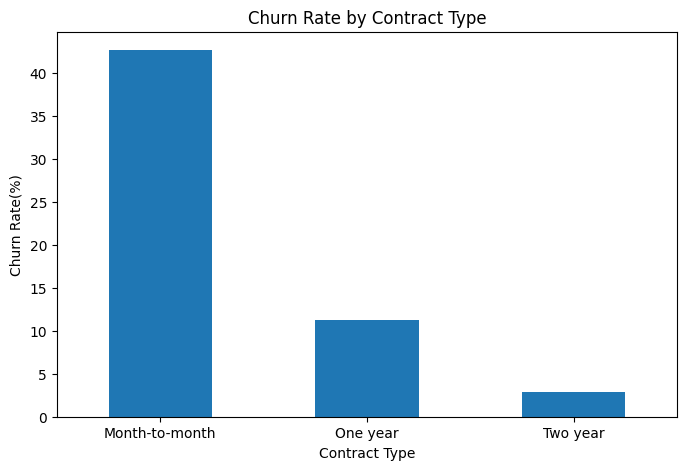

In [26]:
import matplotlib.pyplot as plt

contract_churn_rate = contract_churn['Yes'].sort_values(ascending=False)

plt.figure(figsize=(8,5))
contract_churn_rate.plot(kind='bar')
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate(%)')
plt.xticks(rotation=0)
plt.show()

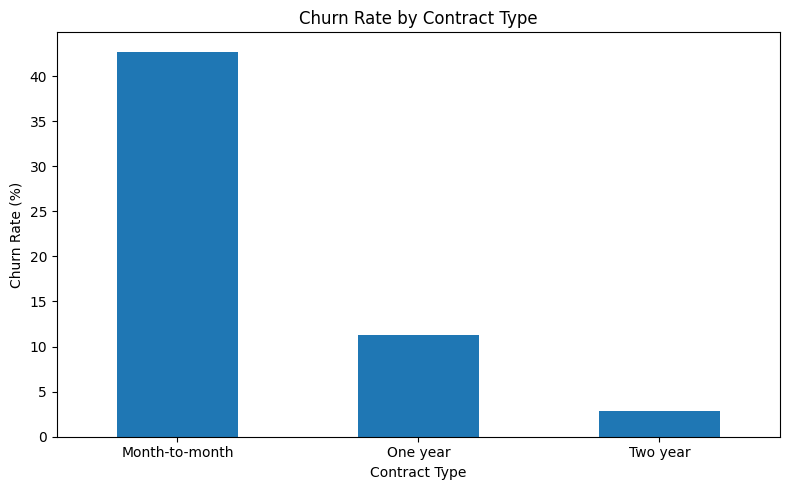

In [27]:
plt.figure(figsize=(8, 5))
contract_churn_rate.plot(kind='bar')
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../reports/figures/churn_rate_by_contract.png')
plt.show()

In [28]:
df_clean.groupby('Churn')['tenure'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [29]:
df_clean.groupby('Churn')['tenure'].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

### Churn and Customer Tenure

Customers who churned had a much lower average tenure than customers who stayed.

- Average tenure for non-churned customers: approximately 37.57 months
- Average tenure for churned customers: approximately 17.98 months

The median tenure also shows a clear difference. Customers who stayed had a median tenure of 38 months, while customers who churned had a median tenure of only 10 months.

This suggests that churn risk is highest among newer customers. From a business perspective, the company should focus on early customer retention, especially within the first year of a customer's relationship.

In [30]:
def tenure_group(tenure):
    if tenure <= 12:
        return '0-12 months'
    elif tenure <= 24:
        return '13-24 months'
    elif tenure <= 48:
        return '25-48 months'
    else:
        return '49+ months'

df_clean['TenureGroup'] = df_clean['tenure'].apply(tenure_group)

In [31]:
tenure_churn = df_clean.groupby('TenureGroup')['Churn'].value_counts(normalize=True).unstack() * 100
tenure_churn['Yes'].sort_values(ascending=False)

TenureGroup
0-12 months     47.438243
13-24 months    28.710938
25-48 months    20.388959
49+ months       9.513176
Name: Yes, dtype: float64

### Churn Rate by Tenure Group

Churn rate decreases as customer tenure increases.

- Customers with 0–12 months tenure have the highest churn rate at approximately 47.44%.
- Customers with 13–24 months tenure have a churn rate of approximately 28.71%.
- Customers with 25–48 months tenure have a churn rate of approximately 20.39%.
- Customers with 49+ months tenure have the lowest churn rate at approximately 9.51%.

This suggests that the first year is the highest-risk period for customer churn. From a business perspective, the company should focus retention efforts on new customers before they disengage. A useful strategy would be to monitor early customer experience, service quality, onboarding, and first-year satisfaction.

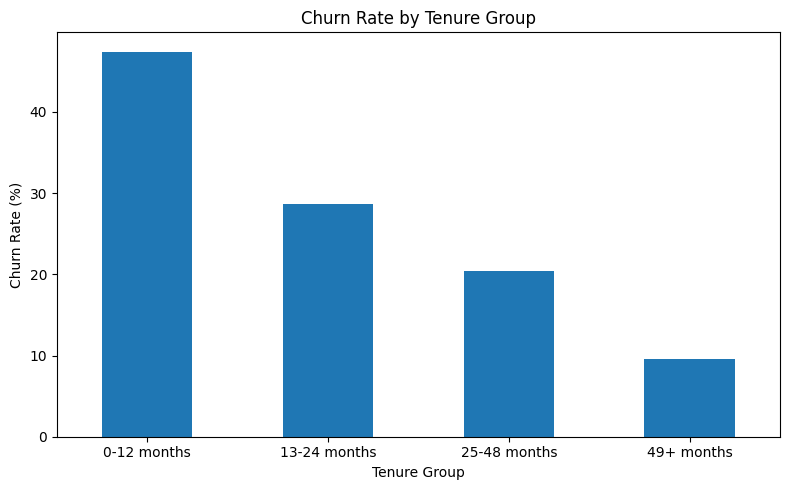

In [32]:
tenure_churn_rate = tenure_churn['Yes'].sort_values(ascending=False)

plt.figure(figsize=(8, 5))
tenure_churn_rate.plot(kind='bar')
plt.title('Churn Rate by Tenure Group')
plt.xlabel('Tenure Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../reports/figures/churn_rate_by_tenure_group.png')
plt.show()

In [33]:
contract_tenure_churn = df_clean.groupby(['Contract', 'TenureGroup'])['Churn'].value_counts(normalize=True).unstack() * 100
contract_tenure_churn['Yes'].sort_values(ascending=False)

Contract        TenureGroup 
Month-to-month  0-12 months     51.354062
                13-24 months    37.720488
                25-48 months    32.917706
                49+ months      26.023392
One year        49+ months      12.933754
                25-48 months    10.617761
                0-12 months     10.483871
                13-24 months     8.121827
Two year        49+ months       3.325416
                25-48 months     2.189781
                0-12 months           NaN
                13-24 months          NaN
Name: Yes, dtype: float64

In [34]:
df_clean.groupby(['Contract', 'TenureGroup']).size()

Contract        TenureGroup 
Month-to-month  0-12 months     1994
                13-24 months     737
                25-48 months     802
                49+ months       342
One year        0-12 months      124
                13-24 months     197
                25-48 months     518
                49+ months       634
Two year        0-12 months       68
                13-24 months      90
                25-48 months     274
                49+ months      1263
dtype: int64

### Segment Size Validation

To avoid making conclusions from small groups, customer counts were checked for each Contract and TenureGroup segment.

The highest-risk segment, month-to-month customers with 0–12 months tenure, contains 1,994 customers. This makes the churn insight meaningful because the segment is both large and high-risk.

This confirms that early-life month-to-month customers should be treated as a priority retention segment.

In [35]:
segment_counts = df_clean.groupby(['Contract', 'TenureGroup']).size().reset_index(name='CustomerCount')
contract_tenure_churn_rate = contract_tenure_churn['Yes'].reset_index()
contract_tenure_churn_rate = contract_tenure_churn_rate.rename(columns={'Yes': 'ChurnRate'})

segment_summary = contract_tenure_churn_rate.merge(
    segment_counts,
    on=['Contract', 'TenureGroup'],
    how='left'
)

segment_summary.sort_values('ChurnRate', ascending=False)

,Contract,TenureGroup,ChurnRate,CustomerCount
0,Month-to-month,0-12 months,51.354062,1994
1,Month-to-month,13-24 months,37.720488,737
2,Month-to-month,25-48 months,32.917706,802
3,Month-to-month,49+ months,26.023392,342
7,One year,49+ months,12.933754,634
6,One year,25-48 months,10.617761,518
4,One year,0-12 months,10.483871,124
5,One year,13-24 months,8.121827,197
11,Two year,49+ months,3.325416,1263
10,Two year,25-48 months,2.189781,274


In [36]:
segment_summary['ChurnRate'] = segment_summary['ChurnRate'].fillna(0)

segment_summary.sort_values('ChurnRate', ascending=False)

,Contract,TenureGroup,ChurnRate,CustomerCount
0,Month-to-month,0-12 months,51.354062,1994
1,Month-to-month,13-24 months,37.720488,737
2,Month-to-month,25-48 months,32.917706,802
3,Month-to-month,49+ months,26.023392,342
7,One year,49+ months,12.933754,634
6,One year,25-48 months,10.617761,518
4,One year,0-12 months,10.483871,124
5,One year,13-24 months,8.121827,197
11,Two year,49+ months,3.325416,1263
10,Two year,25-48 months,2.189781,274


### Contract and Tenure Segment Analysis

The highest-risk segment is customers on month-to-month contracts with 0–12 months tenure. This segment has a churn rate of approximately 51.35% and contains 1,994 customers.

This makes the segment both high-risk and large, meaning it should be the first priority for customer retention efforts.

Month-to-month customers show high churn across all tenure groups, but churn is especially severe during the first year. In contrast, two-year contract customers have very low churn rates.

The `NaN` churn rates for some two-year contract segments were replaced with 0 because those segments had customers but no churned customers recorded.

In [37]:
payment_churn = df_clean.groupby('PaymentMethod')['Churn'].value_counts(normalize=True).unstack() *100
payment_churn['Yes'].sort_values(ascending=False)

PaymentMethod
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Yes, dtype: float64

### Churn Rate by Payment Method

Customers using electronic checks have the highest churn rate at approximately 45.29%.

Churn rates by payment method:

- Electronic check: 45.29%
- Mailed check: 19.11%
- Bank transfer automatic: 16.71%
- Credit card automatic: 15.24%

This suggests that payment method is associated with churn. Customers using automatic payment methods have lower churn rates, while electronic check users are much more likely to churn.

However, this does not prove that electronic check causes churn. The relationship may be influenced by other factors such as contract type, tenure, or customer profile. Further analysis is needed before making a final conclusion.

In [38]:
payment_contract = df_clean.groupby(['PaymentMethod','Contract']).size().reset_index(name='CustomerCount')
payment_contract

,PaymentMethod,Contract,CustomerCount
0,Bank transfer (automatic),Month-to-month,589
1,Bank transfer (automatic),One year,391
2,Bank transfer (automatic),Two year,564
3,Credit card (automatic),Month-to-month,543
4,Credit card (automatic),One year,398
5,Credit card (automatic),Two year,581
6,Electronic check,Month-to-month,1850
7,Electronic check,One year,347
8,Electronic check,Two year,168
9,Mailed check,Month-to-month,893


In [39]:
payment_contract_pct = df_clean.groupby('PaymentMethod')['Contract'].value_counts(normalize=True).unstack() * 100

payment_contract_pct

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),38.147668,25.323834,36.528497
Credit card (automatic),35.676741,26.149803,38.173456
Electronic check,78.224101,14.672304,7.103594
Mailed check,55.397022,20.905707,23.697270


### Payment Method and Contract Type

Electronic check customers have the highest churn rate among payment methods. However, further analysis shows that 78.22% of electronic check customers are on month-to-month contracts.

This is important because month-to-month contracts already have the highest churn rate. Therefore, the high churn among electronic check customers may be partly explained by their contract type.

This is an example of possible confounding. Payment method appears related to churn, but contract type may also be influencing the relationship. More analysis is needed before concluding that payment method independently causes churn.

In [40]:
payment_contract_churn = df_clean.groupby(['PaymentMethod', 'Contract'])['Churn'].value_counts(normalize=True).unstack() * 100

payment_contract_churn['Yes'].sort_values(ascending=False)

PaymentMethod              Contract      
Electronic check           Month-to-month    53.729730
Bank transfer (automatic)  Month-to-month    34.125637
Credit card (automatic)    Month-to-month    32.780847
Mailed check               Month-to-month    31.578947
Electronic check           One year          18.443804
Credit card (automatic)    One year          10.301508
Bank transfer (automatic)  One year           9.718670
Electronic check           Two year           7.738095
Mailed check               One year           6.824926
Bank transfer (automatic)  Two year           3.368794
Credit card (automatic)    Two year           2.237522
Mailed check               Two year           0.785340
Name: Yes, dtype: float64

### Churn by Payment Method and Contract Type

To check whether payment method still matters after considering contract type, churn was analyzed by both `PaymentMethod` and `Contract`.

Among month-to-month customers, electronic check users had the highest churn rate at approximately 53.73%. This is much higher than other month-to-month payment groups:

- Bank transfer automatic: 34.13%
- Credit card automatic: 32.78%
- Mailed check: 31.58%

This suggests that electronic check remains associated with higher churn even within the same contract type.

However, this does not prove that electronic check causes churn. It may still reflect other customer characteristics or service experience issues. Still, payment method appears to be a useful risk signal for churn prediction and customer segmentation.

In [41]:
payment_contract_counts = df_clean.groupby(['PaymentMethod', 'Contract']).size().reset_index(name='CustomerCount')

payment_contract_churn_rate = payment_contract_churn['Yes'].reset_index()
payment_contract_churn_rate = payment_contract_churn_rate.rename(columns={'Yes': 'ChurnRate'})

payment_contract_summary = payment_contract_churn_rate.merge(
    payment_contract_counts,
    on=['PaymentMethod', 'Contract'],
    how='left'
)

payment_contract_summary.sort_values('ChurnRate', ascending=False)

,PaymentMethod,Contract,ChurnRate,CustomerCount
6,Electronic check,Month-to-month,53.729730,1850
0,Bank transfer (automatic),Month-to-month,34.125637,589
3,Credit card (automatic),Month-to-month,32.780847,543
9,Mailed check,Month-to-month,31.578947,893
7,Electronic check,One year,18.443804,347
4,Credit card (automatic),One year,10.301508,398
1,Bank transfer (automatic),One year,9.718670,391
8,Electronic check,Two year,7.738095,168
10,Mailed check,One year,6.824926,337
2,Bank transfer (automatic),Two year,3.368794,564


### Payment Method and Contract Segment Analysis

The highest-risk payment-contract segment is customers using electronic check with month-to-month contracts.

This group has a churn rate of approximately 53.73% and contains 1,850 customers.

This makes it both a high-risk and high-volume segment. From a business perspective, these customers should be prioritized for retention action.

Compared to other month-to-month customers, electronic check users churn at a noticeably higher rate:

- Electronic check + Month-to-month: 53.73%
- Bank transfer automatic + Month-to-month: 34.13%
- Credit card automatic + Month-to-month: 32.78%
- Mailed check + Month-to-month: 31.58%

This suggests that electronic check is a useful churn risk signal, especially among month-to-month customers.

In [42]:
risk_segment_churn = df_clean.groupby(
    ['Contract', 'TenureGroup', 'PaymentMethod']
)['Churn'].value_counts(normalize=True).unstack() * 100

risk_segment_churn_rate = risk_segment_churn['Yes'].reset_index()
risk_segment_churn_rate = risk_segment_churn_rate.rename(columns={'Yes': 'ChurnRate'})

risk_segment_counts = df_clean.groupby(
    ['Contract', 'TenureGroup', 'PaymentMethod']
).size().reset_index(name='CustomerCount')

risk_segment_summary = risk_segment_churn_rate.merge(
    risk_segment_counts,
    on=['Contract', 'TenureGroup', 'PaymentMethod'],
    how='left'
)

risk_segment_summary['ChurnRate'] = risk_segment_summary['ChurnRate'].fillna(0)

risk_segment_summary.sort_values('ChurnRate', ascending=False).head(15)

,Contract,TenureGroup,PaymentMethod,ChurnRate,CustomerCount
2,Month-to-month,0-12 months,Electronic check,63.102725,954
6,Month-to-month,13-24 months,Electronic check,51.267606,355
0,Month-to-month,0-12 months,Bank transfer (automatic),48.557692,208
1,Month-to-month,0-12 months,Credit card (automatic),41.361257,191
10,Month-to-month,25-48 months,Electronic check,40.957447,376
3,Month-to-month,0-12 months,Mailed check,37.753510,641
14,Month-to-month,49+ months,Electronic check,33.939394,165
5,Month-to-month,13-24 months,Credit card (automatic),31.404959,121
8,Month-to-month,25-48 months,Bank transfer (automatic),30.232558,172
9,Month-to-month,25-48 months,Credit card (automatic),27.672956,159


### Combined Risk Segment Analysis

To identify the most important churn segments, contract type, tenure group, and payment method were analyzed together.

The highest-risk meaningful segment is customers who are:

- On month-to-month contracts
- Within their first 12 months
- Using electronic check as their payment method

This segment has a churn rate of approximately 63.10% and contains 954 customers.

This is a major business finding because the segment is both high-risk and large enough to justify targeted retention action.

A recommended retention strategy would be to prioritize these customers for early onboarding support, service quality checks, loyalty incentives, and offers to switch to automatic payment or longer-term contracts.

In [43]:
risk_segment_summary['ExpectedChurnedCustomers'] = (
    risk_segment_summary['ChurnRate'] / 100 * risk_segment_summary['CustomerCount']
)

risk_segment_summary.sort_values('ExpectedChurnedCustomers', ascending=False).head(15)

,Contract,TenureGroup,PaymentMethod,ChurnRate,CustomerCount,ExpectedChurnedCustomers
2,Month-to-month,0-12 months,Electronic check,63.102725,954,602.0
3,Month-to-month,0-12 months,Mailed check,37.753510,641,242.0
6,Month-to-month,13-24 months,Electronic check,51.267606,355,182.0
10,Month-to-month,25-48 months,Electronic check,40.957447,376,154.0
0,Month-to-month,0-12 months,Bank transfer (automatic),48.557692,208,101.0
1,Month-to-month,0-12 months,Credit card (automatic),41.361257,191,79.0
14,Month-to-month,49+ months,Electronic check,33.939394,165,56.0
8,Month-to-month,25-48 months,Bank transfer (automatic),30.232558,172,52.0
9,Month-to-month,25-48 months,Credit card (automatic),27.672956,159,44.0
5,Month-to-month,13-24 months,Credit card (automatic),31.404959,121,38.0


### Expected Churned Customers by Segment

To prioritize retention efforts, churn rate alone is not enough. A customer segment may have a high churn rate but contain very few customers. Therefore, expected churned customers were calculated by multiplying churn rate by customer count.

The largest churn-contributing segment is:

- Contract: Month-to-month
- Tenure group: 0–12 months
- Payment method: Electronic check
- Churn rate: 63.10%
- Customer count: 954
- Expected churned customers: approximately 602

This segment contributes the highest estimated number of churned customers and should be the top priority for retention campaigns.

The second largest churn-contributing segment is month-to-month customers with 0–12 months tenure using mailed check, contributing approximately 242 churned customers.

This confirms that the company’s churn problem is concentrated mainly among new month-to-month customers, especially those using electronic check.

In [44]:
top_risk_segments = risk_segment_summary.sort_values(
    'ExpectedChurnedCustomers',
    ascending=False
).head(15)

top_risk_segments

,Contract,TenureGroup,PaymentMethod,ChurnRate,CustomerCount,ExpectedChurnedCustomers
2,Month-to-month,0-12 months,Electronic check,63.102725,954,602.0
3,Month-to-month,0-12 months,Mailed check,37.753510,641,242.0
6,Month-to-month,13-24 months,Electronic check,51.267606,355,182.0
10,Month-to-month,25-48 months,Electronic check,40.957447,376,154.0
0,Month-to-month,0-12 months,Bank transfer (automatic),48.557692,208,101.0
1,Month-to-month,0-12 months,Credit card (automatic),41.361257,191,79.0
14,Month-to-month,49+ months,Electronic check,33.939394,165,56.0
8,Month-to-month,25-48 months,Bank transfer (automatic),30.232558,172,52.0
9,Month-to-month,25-48 months,Credit card (automatic),27.672956,159,44.0
5,Month-to-month,13-24 months,Credit card (automatic),31.404959,121,38.0


In [45]:
top_risk_segments['Segment'] = (
    top_risk_segments['Contract'] + ' | ' +
    top_risk_segments['TenureGroup'] + ' | ' +
    top_risk_segments['PaymentMethod']
)

top_risk_segments[['Segment', 'ChurnRate', 'CustomerCount', 'ExpectedChurnedCustomers']]

,Segment,ChurnRate,CustomerCount,ExpectedChurnedCustomers
2,Month-to-month | 0-12 months | Electronic check,63.102725,954,602.0
3,Month-to-month | 0-12 months | Mailed check,37.753510,641,242.0
6,Month-to-month | 13-24 months | Electronic check,51.267606,355,182.0
10,Month-to-month | 25-48 months | Electronic check,40.957447,376,154.0
0,Month-to-month | 0-12 months | Bank transfer (...,48.557692,208,101.0
1,Month-to-month | 0-12 months | Credit card (au...,41.361257,191,79.0
14,Month-to-month | 49+ months | Electronic check,33.939394,165,56.0
8,Month-to-month | 25-48 months | Bank transfer ...,30.232558,172,52.0
9,Month-to-month | 25-48 months | Credit card (a...,27.672956,159,44.0
5,Month-to-month | 13-24 months | Credit card (a...,31.404959,121,38.0


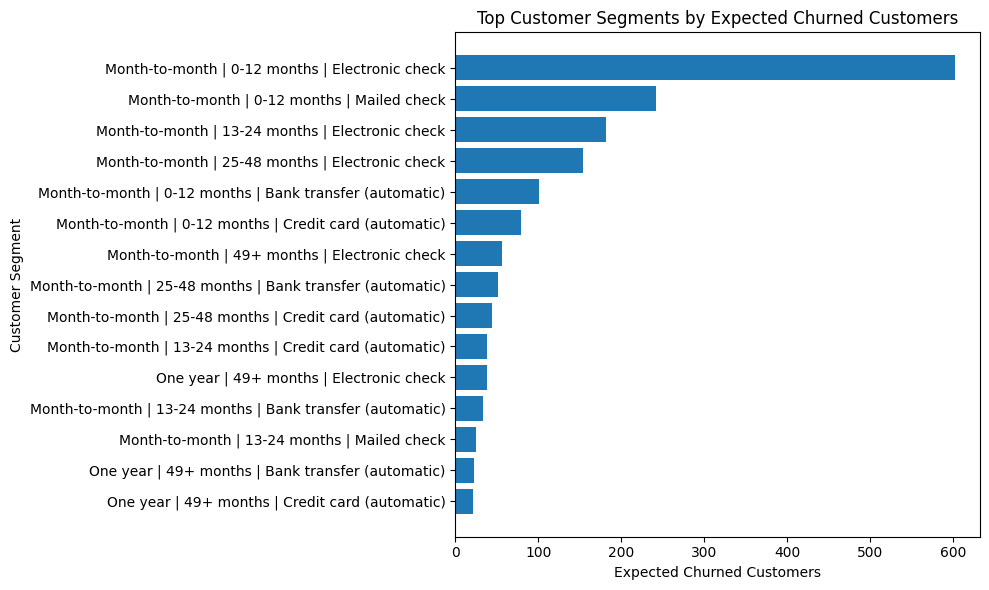

In [46]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_risk_segments['Segment'],
    top_risk_segments['ExpectedChurnedCustomers']
)

plt.title('Top Customer Segments by Expected Churned Customers')
plt.xlabel('Expected Churned Customers')
plt.ylabel('Customer Segment')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('../reports/figures/top_segments_expected_churn.png')
plt.show()

## Key Insights So Far

### 1. Overall churn rate

The dataset contains 7,043 customers. Out of these customers, 1,869 churned.

This gives an overall churn rate of approximately 26.54%, meaning roughly 1 in 4 customers left the telecom company.

### 2. Contract type is strongly associated with churn

Customers on month-to-month contracts have the highest churn rate at approximately 42.71%.

Customers on longer-term contracts churn much less:

- Month-to-month: 42.71%
- One year: 11.27%
- Two year: 2.83%

This suggests that customers with less contractual commitment are much more likely to leave.

### 3. New customers are the highest-risk tenure group

Customers with 0–12 months tenure have the highest churn rate at approximately 47.44%.

Churn decreases as tenure increases:

- 0–12 months: 47.44%
- 13–24 months: 28.71%
- 25–48 months: 20.39%
- 49+ months: 9.51%

This suggests that churn risk is highest during the first year of the customer relationship.

### 4. Electronic check customers have high churn

Customers using electronic check have the highest churn rate among payment methods at approximately 45.29%.

However, further analysis showed that many electronic check customers are also on month-to-month contracts, so payment method should not be interpreted in isolation.

### 5. The highest-risk customer segment

The highest-risk meaningful segment is:

- Contract: Month-to-month
- Tenure group: 0–12 months
- Payment method: Electronic check
- Churn rate: 63.10%
- Customer count: 954
- Expected churned customers: approximately 602

This segment should be the top retention priority because it is both high-risk and large enough to have major business impact.

### 6. Business recommendation

The company should prioritize retention campaigns for new month-to-month customers, especially those using electronic check.

Possible actions include:

- improved onboarding during the first year
- service quality check-ins
- loyalty incentives
- offers to move customers to automatic payment methods
- incentives to upgrade from month-to-month to longer-term contracts

In [47]:
df_clean.groupby('Churn')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


### Monthly Charges and Churn

Customers who churned had higher monthly charges on average than customers who stayed.

- Average monthly charge for non-churned customers: approximately 61.27
- Average monthly charge for churned customers: approximately 74.44
- Difference: approximately 13.17

The median monthly charge was also higher among churned customers:

- Median monthly charge for non-churned customers: approximately 64.43
- Median monthly charge for churned customers: approximately 79.65

This suggests that higher monthly charges are associated with churn. However, this does not prove that price alone causes churn. Higher charges may be related to other factors such as internet service type, contract type, or additional services.

In [48]:
def charge_group(charge):
    if charge < 35:
        return 'Low charge'
    elif charge < 70:
        return 'Medium charge'
    else:
        return 'High charge'

df_clean['ChargeGroup'] = df_clean['MonthlyCharges'].apply(charge_group)

In [49]:
charge_churn = df_clean.groupby('ChargeGroup')['Churn'].value_counts(normalize=True).unstack() * 100

charge_churn['Yes'].sort_values(ascending=False)

ChargeGroup
High charge      35.477583
Medium charge    23.649041
Low charge       10.860774
Name: Yes, dtype: float64

### Churn Rate by Monthly Charge Group

Customers with higher monthly charges have the highest churn rate.

- High charge customers: 35.48%
- Medium charge customers: 23.65%
- Low charge customers: 10.86%

This suggests that monthly charges are associated with churn. Customers paying higher monthly fees are more likely to leave.

However, this does not prove that high monthly charges directly cause churn. Higher charges may be connected to other factors such as contract type, internet service type, or additional services. Further analysis is needed to understand whether high charges remain important after considering other customer characteristics.

In [50]:
charge_contract_churn = df_clean.groupby(
    ['ChargeGroup', 'Contract']
)['Churn'].value_counts(normalize=True).unstack() * 100

charge_contract_churn['Yes'].sort_values(ascending=False)

ChargeGroup    Contract      
High charge    Month-to-month    52.804183
Medium charge  Month-to-month    34.957826
Low charge     Month-to-month    24.289773
High charge    One year          17.548747
Medium charge  One year           7.567568
High charge    Two year           4.811443
Low charge     One year           3.116883
Medium charge  Two year           2.112676
Low charge     Two year           0.778816
Name: Yes, dtype: float64

### Monthly Charge and Contract Type

Monthly charge level remains associated with churn even after considering contract type.

Among month-to-month customers:

- High charge customers have a churn rate of approximately 52.80%.
- Medium charge customers have a churn rate of approximately 34.96%.
- Low charge customers have a churn rate of approximately 24.29%.

This suggests that high monthly charges are a useful churn signal, especially among month-to-month customers.

The highest-risk profile is becoming clearer: customers on month-to-month contracts, with short tenure, using electronic check, and paying high monthly charges are the most likely to churn.

In [51]:
full_risk_churn = df_clean.groupby(
    ['Contract', 'TenureGroup', 'PaymentMethod', 'ChargeGroup']
)['Churn'].value_counts(normalize=True).unstack() * 100

full_risk_churn_rate = full_risk_churn['Yes'].reset_index()
full_risk_churn_rate = full_risk_churn_rate.rename(columns={'Yes': 'ChurnRate'})

full_risk_counts = df_clean.groupby(
    ['Contract', 'TenureGroup', 'PaymentMethod', 'ChargeGroup']
).size().reset_index(name='CustomerCount')

full_risk_summary = full_risk_churn_rate.merge(
    full_risk_counts,
    on=['Contract', 'TenureGroup', 'PaymentMethod', 'ChargeGroup'],
    how='left'
)

full_risk_summary['ChurnRate'] = full_risk_summary['ChurnRate'].fillna(0)

full_risk_summary['ExpectedChurnedCustomers'] = (
    full_risk_summary['ChurnRate'] / 100 * full_risk_summary['CustomerCount']
)

full_risk_summary.sort_values('ExpectedChurnedCustomers', ascending=False).head(15)

,Contract,TenureGroup,PaymentMethod,ChargeGroup,ChurnRate,CustomerCount,ExpectedChurnedCustomers
6,Month-to-month,0-12 months,Electronic check,High charge,70.238095,588,413.0
18,Month-to-month,13-24 months,Electronic check,High charge,57.812500,256,148.0
8,Month-to-month,0-12 months,Electronic check,Medium charge,53.136531,271,144.0
30,Month-to-month,25-48 months,Electronic check,High charge,47.945205,292,140.0
11,Month-to-month,0-12 months,Mailed check,Medium charge,42.396313,217,92.0
10,Month-to-month,0-12 months,Mailed check,Low charge,25.889968,309,80.0
9,Month-to-month,0-12 months,Mailed check,High charge,60.869565,115,70.0
0,Month-to-month,0-12 months,Bank transfer (automatic),High charge,79.268293,82,65.0
42,Month-to-month,49+ months,Electronic check,High charge,36.231884,138,50.0
3,Month-to-month,0-12 months,Credit card (automatic),High charge,62.666667,75,47.0


### Full Risk Profile Analysis

The strongest churn-contributing customer profile is:

- Contract: Month-to-month
- Tenure group: 0–12 months
- Payment method: Electronic check
- Charge group: High charge

This segment has:

- Churn rate: approximately 70.24%
- Customer count: 588
- Expected churned customers: approximately 413

This means that about 7 out of 10 customers in this profile churned.

This segment is the top retention priority because it combines high churn risk with meaningful customer volume. The company should prioritize new high-charge month-to-month customers using electronic check for retention campaigns.

Possible business actions include:

- early onboarding support within the first 12 months
- service quality check-ins
- targeted loyalty discounts
- offers to move from month-to-month to longer-term contracts
- incentives to switch to automatic payment methods
- customer satisfaction surveys for high-charge customers

This analysis identifies high-risk customer profiles but does not prove causation. The findings should be used to guide retention experiments and further investigation.

In [52]:
top_full_risk_segments = full_risk_summary.sort_values(
    'ExpectedChurnedCustomers',
    ascending=False
).head(15)

top_full_risk_segments

,Contract,TenureGroup,PaymentMethod,ChargeGroup,ChurnRate,CustomerCount,ExpectedChurnedCustomers
6,Month-to-month,0-12 months,Electronic check,High charge,70.238095,588,413.0
18,Month-to-month,13-24 months,Electronic check,High charge,57.812500,256,148.0
8,Month-to-month,0-12 months,Electronic check,Medium charge,53.136531,271,144.0
30,Month-to-month,25-48 months,Electronic check,High charge,47.945205,292,140.0
11,Month-to-month,0-12 months,Mailed check,Medium charge,42.396313,217,92.0
10,Month-to-month,0-12 months,Mailed check,Low charge,25.889968,309,80.0
9,Month-to-month,0-12 months,Mailed check,High charge,60.869565,115,70.0
0,Month-to-month,0-12 months,Bank transfer (automatic),High charge,79.268293,82,65.0
42,Month-to-month,49+ months,Electronic check,High charge,36.231884,138,50.0
3,Month-to-month,0-12 months,Credit card (automatic),High charge,62.666667,75,47.0


In [53]:
top_full_risk_segments['Segment'] = (
    top_full_risk_segments['Contract'] + ' | ' +
    top_full_risk_segments['TenureGroup'] + ' | ' +
    top_full_risk_segments['PaymentMethod'] + ' | ' +
    top_full_risk_segments['ChargeGroup']
)

top_full_risk_segments[
    ['Segment', 'ChurnRate', 'CustomerCount', 'ExpectedChurnedCustomers']
]

,Segment,ChurnRate,CustomerCount,ExpectedChurnedCustomers
6,Month-to-month | 0-12 months | Electronic chec...,70.238095,588,413.0
18,Month-to-month | 13-24 months | Electronic che...,57.812500,256,148.0
8,Month-to-month | 0-12 months | Electronic chec...,53.136531,271,144.0
30,Month-to-month | 25-48 months | Electronic che...,47.945205,292,140.0
11,Month-to-month | 0-12 months | Mailed check | ...,42.396313,217,92.0
10,Month-to-month | 0-12 months | Mailed check | ...,25.889968,309,80.0
9,Month-to-month | 0-12 months | Mailed check | ...,60.869565,115,70.0
0,Month-to-month | 0-12 months | Bank transfer (...,79.268293,82,65.0
42,Month-to-month | 49+ months | Electronic check...,36.231884,138,50.0
3,Month-to-month | 0-12 months | Credit card (au...,62.666667,75,47.0


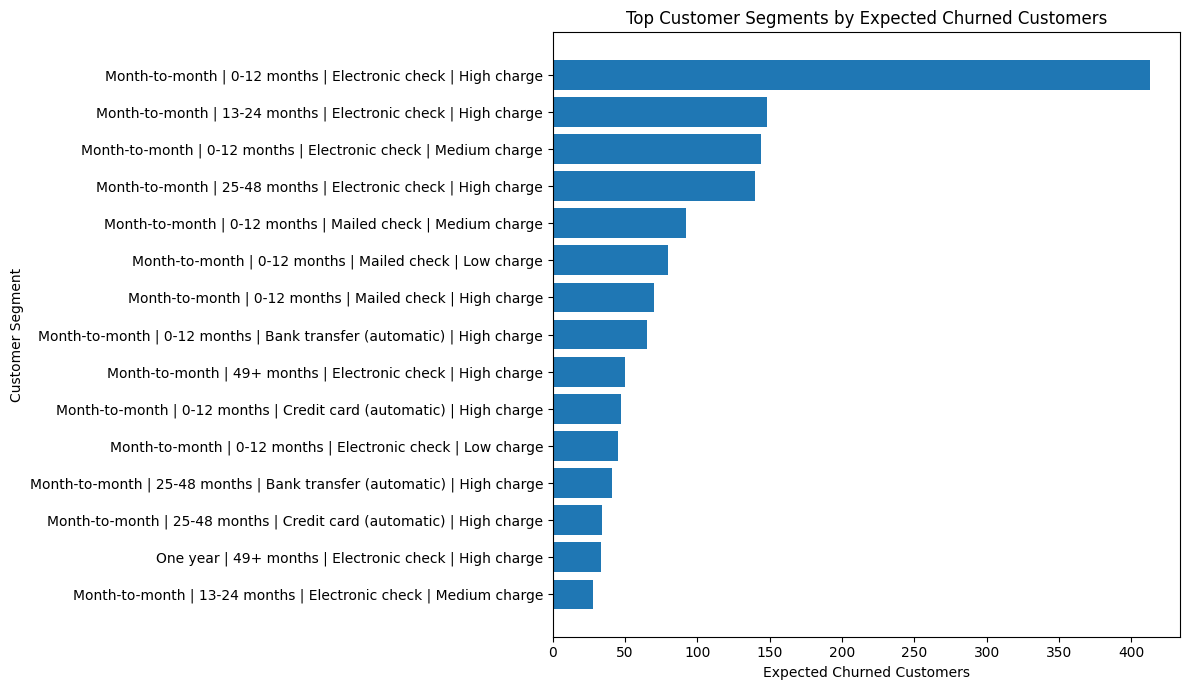

In [54]:
plt.figure(figsize=(12, 7))

plt.barh(
    top_full_risk_segments['Segment'],
    top_full_risk_segments['ExpectedChurnedCustomers']
)

plt.title('Top Customer Segments by Expected Churned Customers')
plt.xlabel('Expected Churned Customers')
plt.ylabel('Customer Segment')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('../reports/figures/top_full_risk_segments_expected_churn.png')
plt.show()

In [55]:
model_df = df_clean.copy()

In [56]:
df_clean.copy()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,ChargeGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 months,Low charge
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48 months,Medium charge
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 months,Medium charge
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48 months,Medium charge
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 months,High charge
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,13-24 months,High charge
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,49+ months,High charge
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,0-12 months,Low charge
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,0-12 months,High charge


In [57]:
model_df = model_df.drop('customerID', axis=1)

In [59]:
model_df['Churn'] = model_df['Churn'].map({'No':0, 'Yes':1})

In [60]:
model_df.select_dtypes(include='object').columns

C:\Users\Jayson Shammah\AppData\Local\Temp\ipykernel_8868\1167613285.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  model_df.select_dtypes(include='object').columns


Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'TenureGroup', 'ChargeGroup'],
      dtype='str')

In [61]:
model_df_encoded = pd.get_dummies(model_df, drop_first=True)

In [62]:
model_df_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_13-24 months,TenureGroup_25-48 months,TenureGroup_49+ months,ChargeGroup_Low charge,ChargeGroup_Medium charge
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,True,False,True,False,False,False,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,True,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,True,False,False,True,False,False,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,False,False,True,False,False,True
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,True,False,True,False,False,False,False,False,False


In [64]:
model_df_encoded.shape

(7043, 36)

In [65]:
model_df_encoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 36 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   SeniorCitizen                          7043 non-null   int64  
 1   tenure                                 7043 non-null   int64  
 2   MonthlyCharges                         7043 non-null   float64
 3   TotalCharges                           7043 non-null   float64
 4   Churn                                  7043 non-null   int64  
 5   gender_Male                            7043 non-null   bool   
 6   Partner_Yes                            7043 non-null   bool   
 7   Dependents_Yes                         7043 non-null   bool   
 8   PhoneService_Yes                       7043 non-null   bool   
 9   MultipleLines_No phone service         7043 non-null   bool   
 10  MultipleLines_Yes                      7043 non-null   bool   
 11  InternetService

In [67]:
X = model_df_encoded.drop('Churn', axis= 1)
y = model_df_encoded['Churn']

In [68]:
X.shape

(7043, 35)

In [69]:
y.shape

(7043,)

In [73]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.0-cp314-cp314-win_amd64.whl.metadata (11 kB)
  Using cached scipy-1.17.1-cp314-cp314-win_amd64.whl.metadata (60 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
Using cached scikit_learn-1.9.0-cp314-cp314-win_amd64.whl (8.3 MB)
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
Using cached scipy-1.17.1-cp314-cp314-win_amd64.whl (37.3 MB)
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)

   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- --------------------


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [74]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y

) 

In [75]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5634, 35), (1409, 35), (5634,), (1409,))

In [76]:
y_train.value_counts(normalize=True) * 100

Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

In [77]:
y_test.value_counts(normalize=True) * 100

Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64

### Train-Test Split

The dataset was split into training and testing sets using an 80/20 split.

Stratified sampling was used to preserve the original churn distribution in both sets.

The churn distribution remained almost identical:

Training set:
- No churn: approximately 73.46%
- Churn: approximately 26.54%

Test set:
- No churn: approximately 73.46%
- Churn: approximately 26.54%

This is important because churn is imbalanced. Only about 26.5% of customers churned, so preserving this class balance helps make model evaluation more reliable.

In [78]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

c:\Users\Jayson Shammah\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [79]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features)
    ],
    remainder='passthrough'
)

log_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(max_iter=2000))
    ]
)

log_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](35,)","['SeniorCitizen','tenure','MonthlyCharges',...,'TenureGroup_49+ months', 'ChargeGroup_Low charge','ChargeGroup_Medium charge']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,35
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

In [80]:
y_pred = log_model.predict(X_test)

In [81]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
accuracy

0.7998580553584103

### Baseline Logistic Regression Model

A Logistic Regression model was trained as the first baseline classification model.

The model achieved an accuracy of approximately 80.0% on the test set.

However, accuracy alone is not enough for churn prediction because the dataset is imbalanced. Since about 73.5% of customers did not churn, a model that predicts "No churn" for every customer would already achieve about 73.5% accuracy.

Therefore, the model must also be evaluated using precision, recall, F1-score, and a confusion matrix.

In [82]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

cm

array([[932, 103],
       [179, 195]])

In [83]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



### Model Evaluation: Logistic Regression

The Logistic Regression model achieved an accuracy of approximately 80.0%.

The confusion matrix was:

- True negatives: 932
- False positives: 103
- False negatives: 179
- True positives: 195

The model correctly identified 195 out of 374 churned customers, giving a churn recall of approximately 52%.

For the churn class:

- Precision: 65%
- Recall: 52%
- F1-score: 58%

This means that when the model predicts a customer will churn, it is correct about 65% of the time. However, it only catches about 52% of all actual churners.

From a business perspective, this model is useful as a baseline, but it may miss too many churners for a serious retention campaign. Improving recall should be a priority because missing a customer who is likely to churn means losing the chance to intervene.

In [84]:
y_proba = log_model.predict_proba(X_test)[:, 1]

y_proba[:10]

array([0.04272043, 0.73215445, 0.05139318, 0.33154878, 0.0232048 ,
       0.54236959, 0.38124146, 0.10689785, 0.00454359, 0.31823612])

In [85]:
y_pred_40 = (y_proba >= 0.40).astype(int)

In [86]:
from sklearn.metrics import confusion_matrix, classification_report

cm_40 = confusion_matrix(y_test, y_pred_40)

cm_40

array([[858, 177],
       [128, 246]])

### Business Impact of Threshold Tuning

Lowering the classification threshold from 0.50 to 0.40 increased churn recall from 52% to 66%.

The model correctly identified 51 additional churning customers while reducing missed churners from 179 to 128.

Although false positives increased from 103 to 177, the improvement in churn detection may justify the additional retention effort if retention actions are relatively inexpensive.

This demonstrates the trade-off between precision and recall and highlights the importance of aligning model decisions with business objectives.

In [87]:
print(classification_report(y_test, y_pred_40))

              precision    recall  f1-score   support

           0       0.87      0.83      0.85      1035
           1       0.58      0.66      0.62       374

    accuracy                           0.78      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.78      0.79      1409



### Threshold Tuning

The default Logistic Regression threshold is 0.50. At this threshold, the model achieved approximately 80% accuracy, with churn recall of 52%.

Because churn prediction is mainly concerned with identifying customers who are likely to leave, the threshold was lowered to 0.40.

At the 0.40 threshold:

- Accuracy decreased slightly to approximately 78%.
- Churn precision decreased to 58%.
- Churn recall increased to 66%.
- Churn F1-score improved to 62%.

This means the model catches more actual churners, but it also creates more false positives.

From a business perspective, this may be acceptable if the retention action is low-cost, such as SMS reminders, service quality check-ins, or onboarding support. If the retention action is expensive, the company may need a higher threshold to reduce false positives.

In [88]:
df_clean.to_csv('../data/cleaned/telco_churn_cleaned.csv', index=False)

In [89]:
model_df_encoded.to_csv('../data/cleaned/telco_churn_model_ready.csv', index=False)

## Key Findings

### 1. Overall churn rate

The dataset contains 7,043 customers, with an overall churn rate of approximately 26.54%.

### 2. Contract type is a major churn driver

Customers on month-to-month contracts have the highest churn rate at approximately 42.71%, compared to 11.27% for one-year contracts and 2.83% for two-year contracts.

### 3. New customers are most at risk

Customers with 0–12 months tenure have the highest churn rate at approximately 47.44%. Churn decreases as tenure increases.

### 4. Payment method matters

Customers using electronic check have the highest churn rate among payment methods at approximately 45.29%.

### 5. Highest-risk segment

The highest-risk customer profile is:

- Month-to-month contract
- 0–12 months tenure
- Electronic check payment method
- High monthly charges

This segment has a churn rate of approximately 70.24% and contributes an estimated 413 churned customers.

## Modeling Summary

A Logistic Regression model was trained as the baseline model.

At the default threshold of 0.50:

- Accuracy: approximately 80%
- Churn precision: 65%
- Churn recall: 52%
- Churn F1-score: 58%

After lowering the threshold to 0.40:

- Accuracy: approximately 78%
- Churn precision: 58%
- Churn recall: 66%
- Churn F1-score: 62%

Lowering the threshold improved the model’s ability to identify churners, which may be useful if retention actions are low-cost.

## Business Recommendation

The company should prioritize retention campaigns for new month-to-month customers, especially those using electronic check and paying high monthly charges.

Possible actions include:

- early onboarding support
- service quality check-ins
- loyalty incentives
- offers to switch to automatic payment methods
- incentives to move to longer-term contracts